# 1. Data sources and data quality

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/energy-grid-technology/procurement-spend-analytics/notebooks/01_data_sources_and_quality.ipynb)

Havelwerk Grid Components is a fictional maker of power transformers with plants in Berlin, Erfurt and Gdansk. Its purchasing data comes from two ERP systems with different formats, a contracts spreadsheet and market price indices. Everything here is synthetic, and the generator plants known data problems so the checks can be scored.

This notebook profiles each source, runs the 12 data quality rules and merges duplicate suppliers into golden records.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "energy-grid-technology/procurement-spend-analytics"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlsxwriter", "python-pptx"], check=True)
else:
    here = Path.cwd()
    while not (here / "src" / "spendcube").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: procurement-spend-analytics


In [2]:
import json
from spendcube import sources as S, suppliers as SU, quality as Q, cube as C, analytics as A, forecast as F, profiling
from spendcube.pipeline import load_indices
raw = S.read_raw()
key = json.loads(Path("data/raw/_answer_key.json").read_text())
recs, merges, review = SU.match(SU.stack_masters(raw))
harmonised = S.harmonise(raw)
lines, clean_log = C.clean(harmonised, recs, raw)
tables = C.build(lines, SU.golden_records(recs))
con = C.to_sqlite(tables)
print({k: len(v) for k, v in raw.items()})

{'erp_a_ekpo': 10703, 'erp_a_lfa1': 114, 'erp_b_orders': 3414, 'erp_b_suppliers': 53, 'goods_receipts': 13147, 'quality_notifications': 178, 'contracts': 38, 'commodity_indices': 94}


## What each source looks like

In [3]:
p = profiling.profile(raw)
p[p.source.isin(["erp_a_ekpo", "erp_b_orders"])][["source", "column", "filled", "distinct", "format", "example"]]

,source,column,filled,distinct,format,example
0,erp_a_ekpo,EBELN,1.0000,10663,number,4500000001
1,erp_a_ekpo,EBELP,1.0000,1,number,00010
2,erp_a_ekpo,BEDAT,1.0000,672,date DD.MM.YYYY,18.11.2024
3,erp_a_ekpo,WERKS,1.0000,2,code,DE10
4,erp_a_ekpo,LIFNR,1.0000,121,number,1000063
5,erp_a_ekpo,MATNR,1.0000,40,code,ES-102
6,erp_a_ekpo,TXZ01,1.0000,40,text,Laser-scribed GOES 0.23 mm
7,erp_a_ekpo,MATKL,1.0000,9,code,ES
8,erp_a_ekpo,MENGE,1.0000,4526,"number, German format","2.038,000"
9,erp_a_ekpo,MEINS,1.0000,4,text,KG


ERP_A writes German number formats and dates, and quotes cheap items per 100 units; ERP_B writes ISO dates and prices in PLN, and leaves the category empty on many lines. Harmonising turns both into EUR per unit:

In [4]:
harmonised[["source", "order_no", "order_date", "supplier_ref", "description", "category", "quantity", "uom", "unit_price_eur"]].sample(6, random_state=1)

,source,order_no,order_date,supplier_ref,description,category,quantity,uom,unit_price_eur
13865,ERP_B,B73163,2026-09-01,PLS-5009,Laser-scribed GOES 0.23 mm,ES,3701.0,KG,4.390698
10128,ERP_A,4500010129,2026-09-01,1000063,Grain-oriented electrical steel 0.23 mm Hi-B,ES,1427.0,KG,3.910800
6835,ERP_A,4500006836,2026-02-19,1000210,Aluminium cast housing,AL,141.0,PC,188.420000
5514,ERP_A,4500005515,2025-11-17,1000112,Steel plate S235 8 mm,ST,1627.0,KG,0.880500
8290,ERP_A,4500008291,2026-05-15,1000567,Sea freight container,LG,2.0,EA,3315.190000
2001,ERP_A,4500002002,2025-03-11,1000245,Natural ester transformer fluid,OI,628.0,L,4.023900


## Data quality rules

In [5]:
dq = Q.run(raw, harmonised, recs, review)
dq[["id", "dataset", "dimension", "rule", "severity", "owner", "checked", "failing"]]

,id,dataset,dimension,rule,severity,owner,checked,failing
0,DQ01,erp_a_ekpo,uniqueness,An order line appears once per export,high,ERP_A data steward (procurement operations),10703,40
1,DQ02,po_lines,validity,Every order line points to a supplier that exists in the supplier master,high,Supplier master data team,14117,12
2,DQ03,erp_b_orders,completeness,Every order line has a material group (category),medium,ERP_B data steward (plant Gdansk purchasing),3414,615
3,DQ04,po_lines,validity,Unit price is within 20x of the median price of the same material,high,Category buyer,14117,20
4,DQ05,erp_b_orders,validity,Order quantity is positive,low,ERP_B data steward (plant Gdansk purchasing),3414,18
5,DQ06,supplier_master,completeness,Every supplier has a country,medium,Supplier master data team,167,14
6,DQ07,supplier_master,uniqueness,One real company has one golden supplier record,high,Supplier master data team,167,52
7,DQ08,supplier_master,consistency,Payment terms use one format that converts to net days,medium,Finance (accounts payable),167,70
8,DQ09,goods_receipts,consistency,A goods receipt is not dated before its order,medium,Warehouse / receiving,13147,15
9,DQ10,po_lines,validity,No orders are placed with a blocked supplier,high,Category buyer and compliance,14117,76


In [6]:
Q.score_against_key(dq, key, SU.evaluate(recs, key))

,planted_problem,planted,found
0,Duplicate order lines in the ERP_A export,40,40
1,Order lines with a supplier missing from the master,12,12
2,ERP_B lines without a category,615,615
3,Copper lines priced per tonne on a per-kg line,20,20
4,Returns booked as negative quantities,18,18
5,Suppliers without a country,14,14
6,Goods receipts dated before the order,15,15
7,Duplicate supplier pairs (within and across ERPs),55,55


In [7]:
Q.scorecard(dq)

dimension,completeness,consistency,uniqueness,validity
dataset,,,,
erp_a_ekpo,NaN,NaN,0.9963,NaN
erp_b_orders,0.8199,NaN,NaN,0.9947
goods_receipts,NaN,0.9989,NaN,NaN
po_lines,NaN,1.0000,NaN,0.9974
supplier_master,0.8862,0.5808,0.6886,NaN


## Supplier matching

Same VAT ID merges automatically. Otherwise the normalised names must match, and a pair that conflicts on VAT ID, legal form or country is left for a person to review.

In [8]:
print(SU.evaluate(recs, key))
merges.groupby("rule").size()

{'true_pairs': 55, 'found': 55, 'false_merges': 0, 'precision': 1.0, 'recall': 1.0, 'records': 167, 'golden_records': 115, 'true_suppliers': 115}


rule
normalised name    19
same VAT ID        33
dtype: int64

In [9]:
review[["name_a", "name_b", "score", "not_merged_because"]].head(8)

,name_a,name_b,score,not_merged_because
0,Ruhr Stahlbau S.A.,Ruhr Stahlbau Sp. z o.o.,1.0,different legal forms
1,Warta Durchfuehrung S.p.A.,Warta Durchfuehrung GmbH,1.0,different VAT IDs
2,Lahn Sensorik GmbH,Lahn Sensorik Co. Ltd.,1.0,different legal forms
3,Inn Spedition GmbH,Inn Spedition S.A.,1.0,different VAT IDs
4,Inn Spedition GmbH,Inn Spedition S.A.,1.0,different VAT IDs
5,Inn Spedition S.A.,INN SPEDITION GMBH,1.0,different VAT IDs
6,Isar Dienste S.A.,Isar Dienste Sp. z o.o.,1.0,different VAT IDs
7,Isar Dienste S.A.,ISAR DIENSTE SP. Z O.O.,1.0,different legal forms


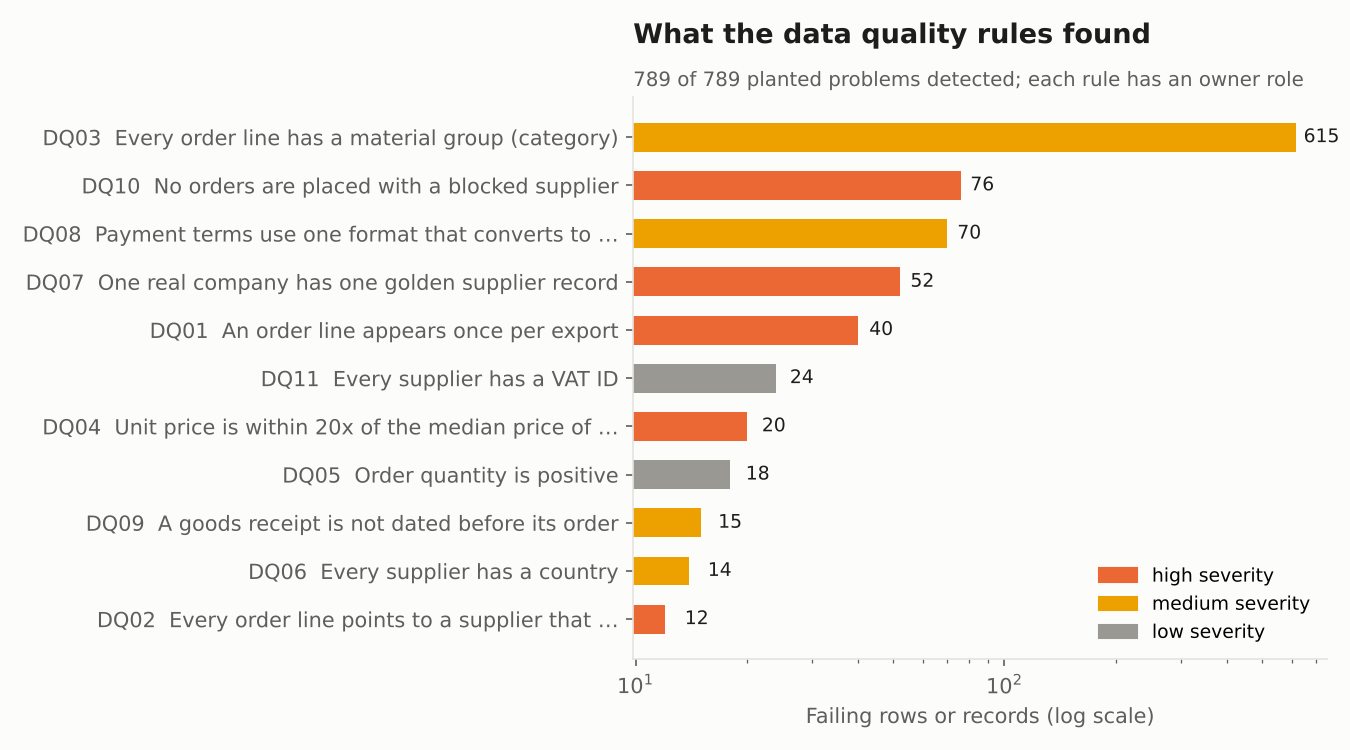

In [10]:
display(Image("outputs/figures/dq_findings.png"))